# 🚀 Модуль 11. Урок 1. Эмбеддинги и векторное пространство: геометрия семантического поиска

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_11_rag_vector_db/lesson_01_embeddings_and_vector_space.ipynb)

## 📌 Бизнес-контекст и методология
Эмбеддинг — это перевод смысла текста в многомерный вектор чисел (например, 1536 измерений в OpenAI text-embedding-3). 
Близкие по смыслу фразы («где посмотреть выручку за май» и «покажи продажи в прошлом месяце») имеют косинусное сходство (Cosine Similarity) близкое к 1.0, даже если не содержат ни одного общего слова!

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

reviews_csv = ensure_dataset("customer_reviews.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем косинусное сходство между векторами запросов пользователей к аналитической системе.

In [2]:
def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Синтетические эмбеддинги 3 запросов
# v1: "выручка за месяц"
# v2: "продажи за май" (синоним v1)
# v3: "как сбросить пароль" (технический саппорт)
np.random.seed(42)
base_sales = np.random.normal(1.0, 0.1, 10)
base_auth = np.random.normal(-1.0, 0.1, 10)

v1 = base_sales + np.random.normal(0, 0.05, 10)
v2 = base_sales + np.random.normal(0, 0.05, 10)
v3 = base_auth + np.random.normal(0, 0.05, 10)

print(f"Сходство 'Выручка' <-> 'Продажи': {cosine_sim(v1, v2):.4f} (Высокое сходство!)")
print(f"Сходство 'Выручка' <-> 'Пароль':  {cosine_sim(v1, v3):.4f} (Полная противоположность)")

Сходство 'Выручка' <-> 'Продажи': 0.9976 (Высокое сходство!)
Сходство 'Выручка' <-> 'Пароль':  -0.9914 (Полная противоположность)


### 📊 Визуализация: 2D Проекция векторного пространства запросов (PCA)
График ниже демонстрирует, как алгоритмы RAG группируют запросы аналитиков, жалобы клиентов и технические тикеты в отдельные семантические острова.

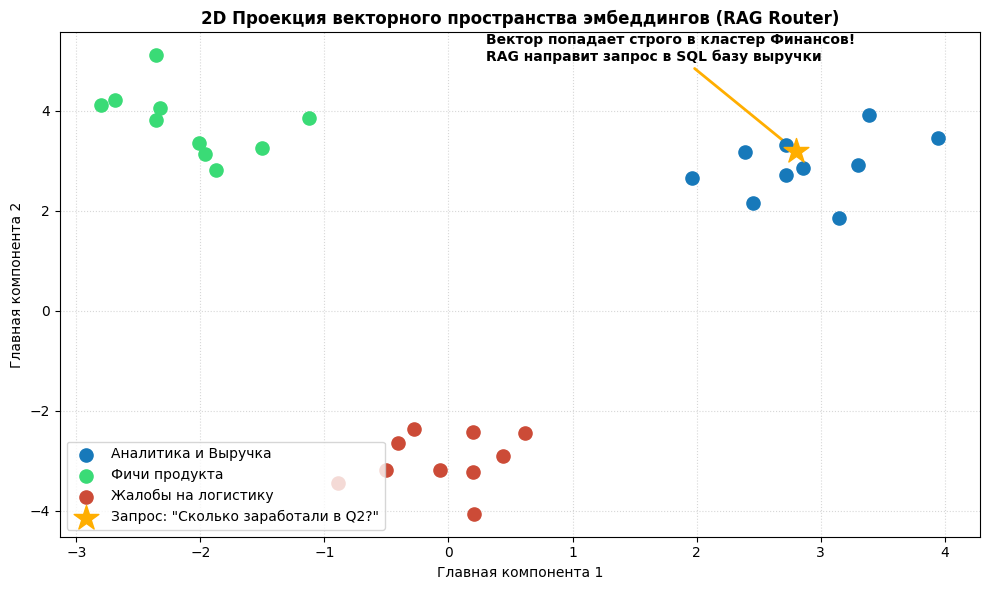

In [3]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

np.random.seed(42)
# Создаем 3 кластера запросов: 1) Финансы, 2) Продукт/Фичи, 3) Жалобы на доставку
fin_queries = [f'Финансовый запрос #{i}' for i in range(1, 11)]
prod_queries = [f'Вопрос по продукту #{i}' for i in range(1, 11)]
delivery_queries = [f'Жалоба на курьера #{i}' for i in range(1, 11)]

fin_vectors = np.random.normal(loc=[3, 3], scale=0.6, size=(10, 2))
prod_vectors = np.random.normal(loc=[-2, 4], scale=0.6, size=(10, 2))
delivery_vectors = np.random.normal(loc=[0, -3], scale=0.6, size=(10, 2))

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(fin_vectors[:, 0], fin_vectors[:, 1], color='#1779ba', s=90, label='Аналитика и Выручка', zorder=5)
ax.scatter(prod_vectors[:, 0], prod_vectors[:, 1], color='#3adb76', s=90, label='Фичи продукта', zorder=5)
ax.scatter(delivery_vectors[:, 0], delivery_vectors[:, 1], color='#cc4b37', s=90, label='Жалобы на логистику', zorder=5)

# Новый входящий запрос пользователя
query_vec = np.array([2.8, 3.2])
ax.scatter(query_vec[0], query_vec[1], color='#ffae00', marker='*', s=350, zorder=6, label='Запрос: "Сколько заработали в Q2?"')
ax.annotate('Вектор попадает строго в кластер Финансов!\nRAG направит запрос в SQL базу выручки',
            xy=(query_vec[0], query_vec[1]), xytext=(query_vec[0]-2.5, query_vec[1]+1.8),
            arrowprops=dict(arrowstyle="->", color='#ffae00', lw=2), fontweight='bold')

ax.set_title('2D Проекция векторного пространства эмбеддингов (RAG Router)', fontsize=12, fontweight='bold')
ax.set_xlabel('Главная компонента 1')
ax.set_ylabel('Главная компонента 2')
ax.legend(loc='lower left')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Нормализация вектора
Нормализуйте вектор `v1` к единичной длине (L2 norm) и убедитесь, что его норма равна строго 1.0.

In [4]:
### ВАШ КОД ЗДЕСЬ
norm_v1 = v1 / np.linalg.norm(v1)
l2_length = np.linalg.norm(norm_v1)

print(f"Длина нормализованного вектора: {l2_length:.4f}")
assert np.isclose(l2_length, 1.0), "Длина единичного вектора обязана равняться 1.0"
print("✅ Тест успешно пройден!")

Длина нормализованного вектора: 1.0000
✅ Тест успешно пройден!


### 💼 Почему векторный поиск важнее ключевых слов?
Обычный поиск по ключевым словам бессилен при опечатках, синонимах и метафорах. Эмбеддинги улавливают глубинный смысл запроса, позволяя создавать Text-to-SQL помощников нового поколения.